# 02 · Baseline: first models and first Kaggle submission

**ML DSBA M2 · Kaggle challenge "Front Row: Who Buys the Ticket?"**

This notebook comes right after `01_EDA.ipynb`. The goal is **not** to get the best score yet. The goal is to:

1. turn the EDA findings into one reusable feature function (same code for train and test)
2. set up the validation we'll use for the whole project (and never change)
3. get three reference points: a "dumb" baseline, logistic regression, LightGBM
4. pick the decision threshold for F1 properly
5. write two submission files and send them to Kaggle

Every later experiment gets compared to the numbers in this notebook.

## TL;DR

| model | features | CV AUC | CV F1 (best threshold) | threshold |
|---|---|---|---|---|
| predict all 1 | - | - | 0.503 | - |
| logistic regression | A raw CSV | 0.658 | 0.537 | 0.26 |
| LightGBM | A raw CSV | 0.697 | 0.559 | 0.27 |
| logistic regression | B = A + EDA | 0.950 | 0.827 | 0.40 |
| **LightGBM** | **B = A + EDA** | **0.959** | **0.842** | **0.44** |

1. **The EDA features are the whole story.** With the raw CSV, LightGBM gets F1 0.559, barely above "everyone buys" (0.503). With the EDA features: 0.842. That's +0.28 F1 from features vs +0.015 from switching logistic regression → LightGBM.
2. **LightGBM is our main model**: 0.842 vs 0.827 for logistic regression. The gap (0.015) is bigger than the fold-to-fold noise (std ≈ 0.006), so it's real, just small.
3. **Threshold 0.44**, not 0.5. For model B the F1 curve is flat between ~0.30 and ~0.50, so the choice isn't fragile.
4. **Weak spot**: users with no listening data (`empty`, `missing`, `no_app`, ~13% of rows). F1 ≈ 0.79 for them vs 0.855 for active users, and the model over-predicts buying there. That's where the next features should go.
5. For reference, the public leaderboard leader is at 0.845 right now. Our 0.842 is a CV score, not a leaderboard score, but we're in the right zone.
6. Two files are ready in `submissions/`: `lgbm_A_raw` (to measure the raw-CSV score on Kaggle too) and `lgbm_B_eda` (our real baseline).

## Contents

1. Setup
2. Load the data (CSV + flattened JSON)
3. Feature building: set A (raw CSV) and set B (A + EDA features)
4. Validation setup: grouped, stratified, fixed folds
5. Model 0: the dumb baselines
6. Model 1: logistic regression (reference)
7. Model 2: LightGBM (main model)
8. Choosing the threshold for F1
9. Results table
10. What is the model looking at?
11. Where does it fail?
12. Final fit and submission files
13. Experiment log + next steps

---
## 1. Setup

Same environment as the EDA (conda base, Python 3.11), plus LightGBM. If it's not installed yet, run this once in the terminal:

```
pip install lightgbm
```

I fix the random seed everywhere and print the library versions, because the grading says the result has to be **reproducible**: the teachers must be able to rerun our code and get the same submission.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import lightgbm as lgb

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
BLUE, GREY, RED, GREEN, ORANGE = "#3b6ea8", "#b5b5b5", "#d1495b", "#2a9d8f", "#e9a03b"

SEED = 42
N_FOLDS = 5
DATA_DIR = Path("ml-dsba-m-2")
OUT_DIR = Path("submissions")
OUT_DIR.mkdir(exist_ok=True)
SNAPSHOT = pd.Timestamp("2026-10-01", tz="UTC")

print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| lightgbm", lgb.__version__)

pandas 2.3.3 | numpy 2.2.6 | sklearn 1.9.1 | lightgbm 4.7.0


---
## 2. Load the data

Same loading as in the EDA. The JSON gets flattened into one row per track play (like `UNNEST` in SQL), and I keep the account status table separately because `empty` and `missing` look identical in the plays.

In [2]:
train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")

with open(DATA_DIR / "music_app.json") as f:
    app = json.load(f)

catalog = pd.DataFrame(app["catalog"]["artists"])
accounts = pd.DataFrame([{"music_app_user_id": a["music_app_user_id"], "app_status": a["activity_status"]}
                         for a in app["accounts"]])
plays = pd.DataFrame([
    {"music_app_user_id": a["music_app_user_id"], "session_id": s["session_id"], **t}
    for a in app["accounts"] for s in a["sessions"] for t in s["tracks"]
])
del app

plays["played_at"] = pd.to_datetime(plays["played_at"])
plays["days_ago"] = (SNAPSHOT - plays["played_at"]).dt.total_seconds() / 86400
plays["completion"] = plays["played_ms"] / plays["track_ms"]
plays["is_search"] = (plays["source"] == "search").astype(int)
plays["saved"] = plays["saved"].astype(int)

print(f"train {train_raw.shape} | test {test_raw.shape} | plays {plays.shape} | accounts {accounts.shape}")

train (30000, 32) | test (20000, 31) | plays (551901, 13) | accounts (9432, 2)


---
## 3. Feature building

Two feature sets, so we can **measure** how much the EDA work is worth (this goes straight into section 1 of the report):

- **Set A, "raw CSV"**: only the columns as given, with the text columns one-hot encoded. No thinking, no JSON. This is what you'd get by just throwing the CSV at a model.
- **Set B, "A + EDA"**: set A plus everything from the feature plan at the end of `01_EDA` (listening features, travel match, price vs usual spend, lead gap, distance, missing flags...).

Important rule: **one function builds the features for both train and test.** That way the preprocessing is guaranteed to be identical (the brief literally asks for this).

Also: nothing in here uses the target `buy`. Every feature is computed from information available before the snapshot, so no leakage.

### 3.1 Listening features (user × artist, from the JSON)

In [3]:
CONCERT_ARTISTS = ["A01", "A02", "A03", "A04", "A05"]


def build_listening_table(plays):
    # one row per (music_app_user_id, concert artist) with the affinity stats from EDA section 10.5
    cp = plays[plays["artist_id"].isin(CONCERT_ARTISTS)].copy()
    cp["in_14d"] = (cp["days_ago"] <= 14).astype(int)
    cp["skip"] = (cp["completion"] < 0.3).astype(int)
    ua = cp.groupby(["music_app_user_id", "artist_id"]).agg(
        art_plays=("artist_id", "size"),
        art_search=("is_search", "sum"),
        art_saved=("saved", "sum"),
        art_completion=("completion", "mean"),
        art_skips=("skip", "sum"),
        art_distinct_tracks=("track_id", "nunique"),
        art_days_since_last=("days_ago", "min"),
        art_plays_14d=("in_14d", "sum"),
    ).reset_index()
    total = plays.groupby("music_app_user_id").size().rename("total_plays").reset_index()
    ua = ua.merge(total, on="music_app_user_id")
    ua["art_share"] = ua["art_plays"] / ua["total_plays"]
    return ua.drop(columns="total_plays")


def build_genre_share(plays):
    # share of each user's plays per genre (EDA section 10.7)
    return pd.crosstab(plays["music_app_user_id"], plays["genre"], normalize="index")


user_artist = build_listening_table(plays)
genre_share = build_genre_share(plays)
user_artist.head()

,music_app_user_id,artist_id,art_plays,art_search,art_saved,art_completion,art_skips,art_distinct_tracks,art_days_since_last,art_plays_14d,art_share
0,M000011A5,A01,4,2,1,0.6572,1,4,9.3904,1,0.0816
1,M000011A5,A03,5,3,2,0.9316,0,5,16.1479,0,0.1020
2,M000011A5,A04,7,5,1,0.8035,0,5,12.2739,1,0.1429
3,M000011A5,A05,2,2,1,0.7462,0,2,9.5363,1,0.0408
4,M00001B55,A02,4,2,0,0.7316,0,4,0.4412,1,0.0400


### 3.2 The feature function

Each block below matches a section of the EDA, so if someone asks "why this feature?", the answer is in `01_EDA` under the same name.

In [4]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def build_features(raw):
    df = raw.copy()

    # --- account status (EDA 10.3): 4 situations, never mix them up
    df = df.merge(accounts, on="music_app_user_id", how="left")
    df["app_status"] = df["app_status"].fillna("no_app")
    df["no_listening_data"] = df["app_status"].isin(["missing", "no_app"]).astype(int)

    # --- listening, user x concert artist (EDA 10.5)
    df = df.merge(user_artist, on=["music_app_user_id", "artist_id"], how="left")
    count_cols = ["art_plays", "art_search", "art_saved", "art_skips", "art_distinct_tracks", "art_plays_14d", "art_share"]
    has_data = df["app_status"].isin(["active", "empty"])
    # active/empty + never played this artist = a real 0. missing / no_app stay NaN (no data != no interest)
    df.loc[has_data, count_cols] = df.loc[has_data, count_cols].fillna(0)
    df["art_skip_rate"] = df["art_skips"] / df["art_plays"].replace(0, np.nan)

    # --- within-user comparison (EDA 10.6): is this my favourite of the 5?
    df["art_rank_in_user"] = df.groupby("user_id")["art_plays"].rank(ascending=False, method="min")
    user_max = df.groupby("user_id")["art_plays"].transform("max").replace(0, np.nan)
    df["art_plays_vs_user_max"] = df["art_plays"] / user_max

    # --- genre taste (EDA 10.7): share of my listening in this concert's genres
    df["genre_affinity"] = np.nan
    ok = df["music_app_user_id"].isin(genre_share.index)
    for genres, idx in df[ok].groupby("genres").groups.items():
        cols = [g for g in genres.split("|") if g in genre_share.columns]
        df.loc[idx, "genre_affinity"] = genre_share.loc[df.loc[idx, "music_app_user_id"], cols].sum(axis=1).values
    df.loc[df["app_status"] == "empty", "genre_affinity"] = 0

    # --- engagement (EDA 9)
    df["visits_missing"] = df["event_page_visits_7d"].isna().astype(int)
    arrival = pd.to_datetime(df["travel_search_arrival"])
    concert_day = pd.to_datetime(df["concert_at"]).dt.tz_localize(None).dt.normalize()
    df["arrival_gap_days"] = (concert_day - arrival).dt.days
    to_venue = df["travel_search_city"] == df["venue_city"]
    df["travel_match"] = (to_venue & (df["arrival_gap_days"].abs() <= 1)).astype(int)
    df["travel_wrong_date"] = (to_venue & (df["arrival_gap_days"].abs() > 1)).astype(int)
    df["travel_other_city"] = (df["travel_search_city"].notna() & ~to_venue).astype(int)

    # --- offer and timing (EDA 7)
    df["total_cost"] = df["ticket_price"] * (1 - df["discount_pct"] / 100) + df["booking_fee"]
    df["price_vs_usual"] = df["total_cost"] / df["typical_ticket_spend"]
    df["price_above_usual"] = (df["price_vs_usual"] > 1).astype(float).where(df["price_vs_usual"].notna())
    df["days_to_concert"] = (pd.to_datetime(df["concert_at"]) - pd.to_datetime(df["prediction_at"])).dt.days
    df["lead_gap"] = df["days_to_concert"] - df["usual_booking_lead_days"]
    df["abs_lead_gap"] = df["lead_gap"].abs()

    # --- geography (EDA 8)
    df["distance_km"] = haversine_km(df["home_lat"], df["home_lon"], df["venue_lat"], df["venue_lon"])
    df["same_city"] = (df["home_city"] == df["venue_city"]).astype(int)

    # --- profile (EDA 6)
    df["fav_genre_match"] = [np.nan if pd.isna(f) else float(f in g.split("|"))
                             for f, g in zip(df["stated_favourite_genre"], df["genres"])]
    return df


train = build_features(train_raw)
test = build_features(test_raw)
assert len(train) == len(train_raw) and len(test) == len(test_raw)          # merges didn't duplicate rows
assert (train["row_id"].values == train_raw["row_id"].values).all()         # row order kept
assert (test["row_id"].values == test_raw["row_id"].values).all()
print("features built:", train.shape, test.shape)

features built: (30000, 61) (20000, 60)


### 3.3 Turning it into model matrices

Text columns need to become numbers. I use **one-hot encoding** (one 0/1 column per category). The category lists come from the train set only, so train and test always get exactly the same columns in the same order.

Blanks stay as `NaN` here on purpose: LightGBM handles them itself, and logistic regression gets its own imputation step inside its pipeline (section 6).

In [5]:
RAW_NUMERIC = ["age", "spending_capacity_band", "past_purchase_count", "first_timer", "typical_ticket_spend",
               "usual_booking_lead_days", "ticket_price", "booking_fee", "discount_pct", "event_page_visits_7d",
               "wishlisted", "home_lat", "home_lon", "venue_lat", "venue_lon"]
RAW_CATEGORICAL = ["education", "home_city", "stated_favourite_genre", "concert_id", "travel_search_city"]

EDA_NUMERIC = [
    # listening
    "art_plays", "art_search", "art_saved", "art_completion", "art_skip_rate", "art_distinct_tracks", "art_share",
    "art_days_since_last", "art_plays_14d", "art_rank_in_user", "art_plays_vs_user_max", "genre_affinity",
    "no_listening_data",
    # engagement
    "visits_missing", "travel_match", "travel_wrong_date", "travel_other_city", "arrival_gap_days",
    # offer & timing
    "total_cost", "price_vs_usual", "price_above_usual", "days_to_concert", "lead_gap", "abs_lead_gap",
    # geography
    "distance_km", "same_city",
    # profile
    "fav_genre_match",
]
EDA_CATEGORICAL = ["app_status"]

FEATURE_SETS = {
    "A_raw": (RAW_NUMERIC, RAW_CATEGORICAL),
    "B_eda": (RAW_NUMERIC + EDA_NUMERIC, RAW_CATEGORICAL + EDA_CATEGORICAL),
}


def make_matrix(df, numeric, categorical, reference=train):
    parts = [df[numeric].astype(float)]
    for c in categorical:
        cats = sorted(reference[c].dropna().unique())                       # categories from TRAIN only
        dummies = pd.get_dummies(pd.Categorical(df[c], categories=cats), prefix=c, dtype=float)
        dummies.index = df.index
        parts.append(dummies)
    return pd.concat(parts, axis=1)


X = {name: make_matrix(train, *cols) for name, cols in FEATURE_SETS.items()}
X_test = {name: make_matrix(test, *cols) for name, cols in FEATURE_SETS.items()}
y = train["buy"].values
groups = train["user_id"].values

for name in X:
    assert list(X[name].columns) == list(X_test[name].columns)
    print(f"{name}: {X[name].shape[1]} columns  ({X[name].isna().any().sum()} with blanks)")

A_raw: 50 columns  (3 with blanks)
B_eda: 81 columns  (21 with blanks)


---
## 4. Validation setup

This is the most important cell of the project, so I want it right from day one and then **never change it**.

**Why grouped?** Each user has 5 rows, and test users are all new people. If a user's rows end up split between training and validation folds, the model can "recognise" the person and the score looks better than it is (we saw it in EDA section 12: 0.61 vs 0.49 in the adversarial test). So all 5 rows of a user must stay in the same fold.

**Why also stratified?** With `StratifiedGroupKFold`, each fold also gets roughly the same buy rate (~33.6%). That makes the per-fold scores more comparable.

**Why fixed?** I compute the folds once and reuse the exact same split for every model and every future experiment. Then if model X beats model Y, it's because of the model, not because X got an easier split.

**OOF (out-of-fold) predictions**: each user is "the exam" exactly once, predicted by a model that never saw them. Stitching the 5 folds together gives one honest prediction per training row. We use those to compare models and to choose the threshold.

In [6]:
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X["A_raw"], y, groups))

check = pd.DataFrame([{
    "fold": k, "train_rows": len(tr), "valid_rows": len(va),
    "valid_users": len(set(groups[va])), "valid_buy_rate": y[va].mean(),
    "users_in_both": len(set(groups[tr]) & set(groups[va])),
} for k, (tr, va) in enumerate(FOLDS)])
check

,fold,train_rows,valid_rows,valid_users,valid_buy_rate,users_in_both
0,0,24000,6000,1200,0.3365,0
1,1,24000,6000,1200,0.3362,0
2,2,24000,6000,1200,0.3360,0
3,3,23995,6005,1201,0.3361,0
4,4,24005,5995,1199,0.3363,0


`users_in_both = 0` for every fold, and the buy rate is ~33.6% everywhere. Good.

Now one helper that runs any model through these folds and returns the OOF probabilities. Every model in this notebook (and later notebooks) goes through this same function.

In [7]:
def run_cv(make_model, X_, name=""):
    # trains one fresh model per fold, returns out-of-fold probabilities + per-fold scores
    oof = np.zeros(len(X_))
    fold_rows = []
    t0 = time.time()
    for k, (tr, va) in enumerate(FOLDS):
        model = make_model()
        model.fit(X_.iloc[tr], y[tr])
        oof[va] = model.predict_proba(X_.iloc[va])[:, 1]
        fold_rows.append({"fold": k, "auc": roc_auc_score(y[va], oof[va]), "f1@0.5": f1_score(y[va], oof[va] >= 0.5)})
    folds = pd.DataFrame(fold_rows)
    print(f"{name:<22} AUC {folds['auc'].mean():.4f} ± {folds['auc'].std():.4f} | "
          f"F1@0.5 {folds['f1@0.5'].mean():.4f} ± {folds['f1@0.5'].std():.4f} | {time.time() - t0:.0f}s")
    return oof, folds


OOF = {}       # name -> oof probabilities
FOLD_SCORES = {}

---
## 5. Model 0: the dumb baselines

Before any real model, the "no brain" reference points from EDA section 4. Anything we build has to beat these, otherwise something is broken.

In [8]:
dumb = pd.DataFrame({
    "model": ["predict all 0", "predict all 1"],
    "F1": [f1_score(y, np.zeros_like(y)), f1_score(y, np.ones_like(y))],
})
dumb

,model,F1
0,predict all 0,0.0000
1,predict all 1,0.5032


---
## 6. Model 1: logistic regression (the reference)

Plain English: give each feature a weight, add everything up, squash the total into a probability between 0 and 1. Positive weight = pushes towards buying.

Logistic regression can't deal with blanks or very different scales by itself, so it gets a small pipeline (lecture 3 + lecture 4 on scaling):

1. `SimpleImputer(strategy="median", add_indicator=True)`: fill blanks with the median **and** add a 0/1 column "this was blank". The second part matters a lot here because blanks carry meaning (EDA section 5).
2. `StandardScaler`: every column gets mean 0 and std 1, so a feature in euros doesn't dominate a feature in counts.
3. `LogisticRegression` with the default L2 regularisation (C = 1).

The pipeline is fitted **inside each fold**, so the median and the scaling are learnt on the training part only. Fitting them on all the data first would leak a tiny bit of the validation fold into training.

In [9]:
def make_logreg():
    return make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=5000),
    )

for fs in FEATURE_SETS:
    OOF[f"logreg_{fs}"], FOLD_SCORES[f"logreg_{fs}"] = run_cv(make_logreg, X[fs], f"logreg_{fs}")

logreg_A_raw           AUC 0.6579 ± 0.0083 | F1@0.5 0.2677 ± 0.0110 | 1s


logreg_B_eda           AUC 0.9500 ± 0.0013 | F1@0.5 0.8203 ± 0.0042 | 3s


---
## 7. Model 2: LightGBM (the main model)

Plain English: a few hundred small decision trees built one after the other, each new tree trying to fix what the previous ones still get wrong. Same family as AdaBoost from lecture 6, but each tree learns the remaining *error* directly (gradient boosting).

Why it fits this data (all from the EDA):
- handles **blanks natively**, so `missing` vs `empty` vs `no_app` is kept as is
- learns **thresholds and humps** by itself (price above usual spend, lead gap)
- learns **interactions** by itself (plays × saved, travel city × date)
- doesn't care about **scale** or correlated features

For the baseline I use reasonable, slightly conservative settings and **no tuning**. Tuning comes later, once the features are stable.

| parameter | value | plain English |
|---|---|---|
| `n_estimators` | 500 | number of trees |
| `learning_rate` | 0.03 | how much each tree is allowed to correct (small = slower but steadier) |
| `num_leaves` | 31 | how complex each tree can get |
| `min_child_samples` | 40 | each leaf needs ≥ 40 rows, so no memorising tiny groups |
| `subsample`, `colsample_bytree` | 0.8 | each tree sees a random 80% of rows / columns (like a random forest, less overfitting) |
| `reg_lambda` | 1.0 | L2 penalty on leaf values (same idea as ridge, lecture 3) |
| `deterministic`, `seed` | True, 42 | same result every run (reproducibility) |

In [10]:
LGB_PARAMS = dict(
    n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=40,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    random_state=SEED, deterministic=True, force_row_wise=True, n_jobs=4, verbose=-1,
)

def make_lgbm():
    return lgb.LGBMClassifier(**LGB_PARAMS)

for fs in FEATURE_SETS:
    OOF[f"lgbm_{fs}"], FOLD_SCORES[f"lgbm_{fs}"] = run_cv(make_lgbm, X[fs], f"lgbm_{fs}")

lgbm_A_raw             AUC 0.6967 ± 0.0056 | F1@0.5 0.3811 ± 0.0051 | 26s


lgbm_B_eda             AUC 0.9586 ± 0.0021 | F1@0.5 0.8390 ± 0.0061 | 32s


Quick read before the threshold part:

- **A (raw CSV)**: AUC 0.66 for logistic regression, 0.70 for LightGBM. And at threshold 0.5 the F1 is terrible (0.27 / 0.38) because the model rarely gets confident enough to say "buy".
- **B (A + EDA)**: AUC jumps to 0.95 / 0.96. Same models, same folds, only the features changed. This is the clearest evidence we have for the report that the feature engineering is what matters.
- The per-fold standard deviations are small (AUC ± 0.001-0.002 for B), so the folds agree with each other.

---
## 8. Choosing the threshold for F1

Every model gives a **probability** ("this person buys with 0.63 chance"). Kaggle wants **0 or 1**. So we need a cut-off: above it → 1, below → 0.

0.5 is just sklearn's default, nothing special about it. For F1 it's usually not the best choice: F1 punishes missed buyers (FN) and false alarms (FP), but gives zero credit for correct "no"s. When the positive class is the minority, it often pays to say "yes" a bit more easily.

How I choose it:
1. take the **OOF probabilities** (honest predictions, section 4)
2. try every threshold from 0.10 to 0.80 in steps of 0.01
3. keep the one with the highest pooled F1 (pooled = over all rows together, exactly like Kaggle computes it)

Then I also check how stable it is: the F1 of each fold at that threshold.

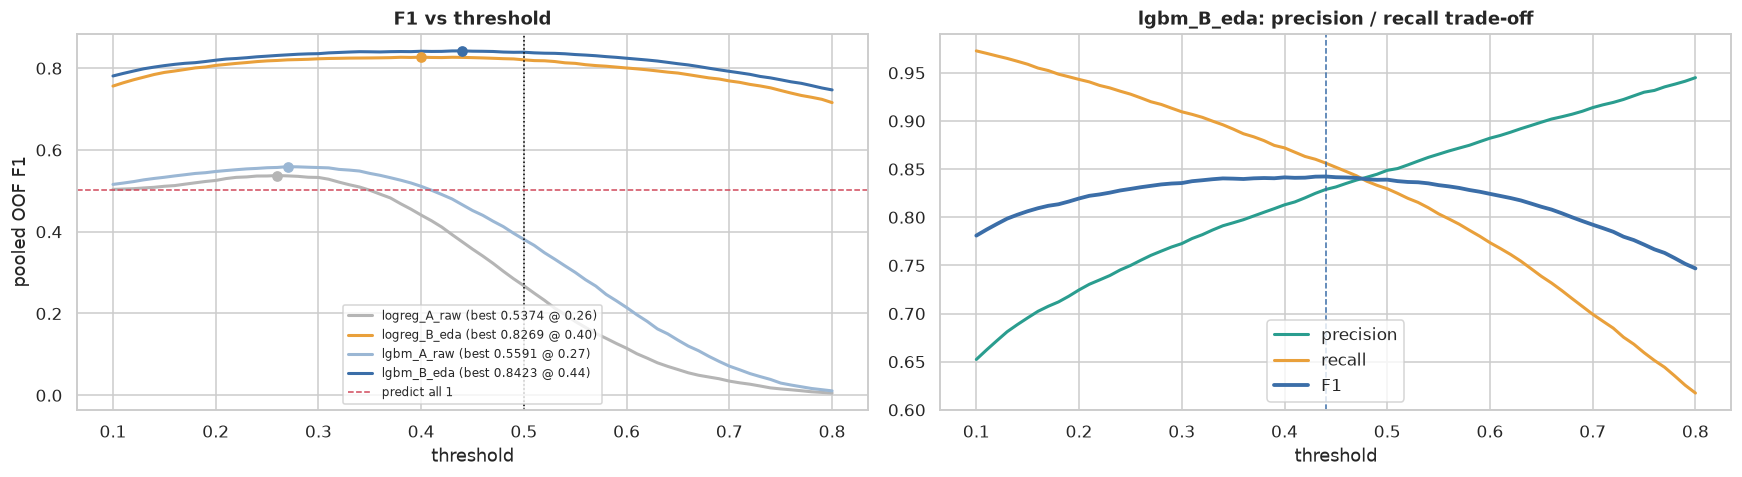

In [11]:
THRESHOLDS = np.round(np.arange(0.10, 0.801, 0.01), 2)


def threshold_curve(p):
    return np.array([f1_score(y, p >= t) for t in THRESHOLDS])


def best_threshold(p):
    curve = threshold_curve(p)
    i = int(np.argmax(curve))
    return THRESHOLDS[i], curve[i], curve


fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
colors = {"logreg_A_raw": GREY, "logreg_B_eda": ORANGE, "lgbm_A_raw": "#9bb7d4", "lgbm_B_eda": BLUE}
BEST_T = {}
for name, p in OOF.items():
    t, f, curve = best_threshold(p)
    BEST_T[name] = t
    axes[0].plot(THRESHOLDS, curve, label=f"{name} (best {f:.4f} @ {t:.2f})", color=colors[name], lw=2)
    axes[0].scatter([t], [f], color=colors[name], zorder=3)
axes[0].axvline(0.5, color="black", ls=":", lw=1)
axes[0].axhline(f1_score(y, np.ones_like(y)), color=RED, ls="--", lw=1, label="predict all 1")
axes[0].set_xlabel("threshold"); axes[0].set_ylabel("pooled OOF F1"); axes[0].set_title("F1 vs threshold")
axes[0].legend(fontsize=8, loc="lower center")

p = OOF["lgbm_B_eda"]
prec = [precision_score(y, p >= t, zero_division=0) for t in THRESHOLDS]
rec = [recall_score(y, p >= t) for t in THRESHOLDS]
axes[1].plot(THRESHOLDS, prec, label="precision", color=GREEN, lw=2)
axes[1].plot(THRESHOLDS, rec, label="recall", color=ORANGE, lw=2)
axes[1].plot(THRESHOLDS, threshold_curve(p), label="F1", color=BLUE, lw=2.5)
axes[1].axvline(BEST_T["lgbm_B_eda"], color=BLUE, ls="--", lw=1)
axes[1].set_xlabel("threshold"); axes[1].set_title("lgbm_B_eda: precision / recall trade-off"); axes[1].legend()
plt.tight_layout(); plt.show()

> **What I take from this**
> - **lgbm_B_eda: best threshold 0.44 → F1 0.8423** (vs 0.8390 at 0.5). The gain from tuning is small here (+0.003) because the model is already well separated. More reassuring: the blue curve is **flat between ~0.30 and ~0.50** (all above 0.835), so even if the "true" best threshold on the private test is a bit different, we don't lose much.
> - The right plot shows the trade-off: lowering the threshold catches more buyers (recall ↑) but adds false alarms (precision ↓). F1 peaks around where the two curves cross.
> - For the raw models the threshold matters a lot more (0.38 → 0.56 for LightGBM A). Their best threshold is ~0.27, which means they predict "buy" for ~61% of rows. In other words they're not far from the "everyone buys" strategy: they don't know much, so saying yes a lot is the best they can do for F1.

---
## 9. Results table

Everything on one table. For each model:
- **AUC** (threshold-free): how well the model *ranks* buyers above non-buyers. Best number to compare models.
- **F1 @ 0.5**: with the default cut-off.
- **F1 @ best threshold**: pooled OOF F1 with the tuned cut-off. This is our best estimate of the Kaggle score.
- **fold std**: how much F1 moves from fold to fold at that threshold. If two models differ by less than this, the difference is probably noise.

In [12]:
rows = [{"model": "predict all 1", "features": "-", "AUC": np.nan, "F1@0.5": f1_score(y, np.ones_like(y)),
         "best_threshold": np.nan, "F1@best": f1_score(y, np.ones_like(y)), "fold_std": np.nan}]
for name, p in OOF.items():
    t = BEST_T[name]
    per_fold = [f1_score(y[va], p[va] >= t) for _, va in FOLDS]
    rows.append({"model": name.split("_")[0], "features": "_".join(name.split("_")[1:]),
                 "AUC": roc_auc_score(y, p), "F1@0.5": f1_score(y, p >= 0.5),
                 "best_threshold": t, "F1@best": f1_score(y, p >= t), "fold_std": np.std(per_fold)})
RESULTS = pd.DataFrame(rows)
RESULTS

,model,features,AUC,F1@0.5,best_threshold,F1@best,fold_std
0,predict all 1,-,NaN,0.5032,NaN,0.5032,NaN
1,logreg,A_raw,0.6578,0.2677,0.2600,0.5374,0.0038
2,logreg,B_eda,0.9499,0.8203,0.4000,0.8269,0.0012
3,lgbm,A_raw,0.6967,0.3811,0.2700,0.5591,0.0049
4,lgbm,B_eda,0.9585,0.8390,0.4400,0.8423,0.0060


> **What I take from this**
> - Ranking: **lgbm_B_eda (0.842) > logreg_B_eda (0.827) >> lgbm_A_raw (0.559) > logreg_A_raw (0.537) > all ones (0.503).**
> - Feature effect (A → B): +0.28 F1 for LightGBM, +0.29 for logistic regression.
> - Model effect (logreg → LightGBM on B): +0.015, about 2.5× the fold std. Real, but small compared to the features. Good sign that the EDA features already capture most of the non-linearity by hand (abs lead gap, travel match, price ratio...), which is exactly what a linear model needs.
> - For the report: this is a nice 2 × 2 table (feature set × model) to show in section 1.

---
## 10. What is the model looking at?

Two different views, one per model.

**LightGBM feature importance (gain)**: how much each feature reduced the loss, summed over all the splits that used it. I average it over the 5 fold models so it's not just one lucky fit. Big caveat: when features are strongly correlated (our play counts), the credit gets shared between them in a somewhat random way, so read it as "this group matters", not as an exact ranking.

**Logistic regression coefficients**: since all features are standardised, the coefficient size is roughly comparable. Positive = pushes towards buying. Also with the same caveat for correlated features.

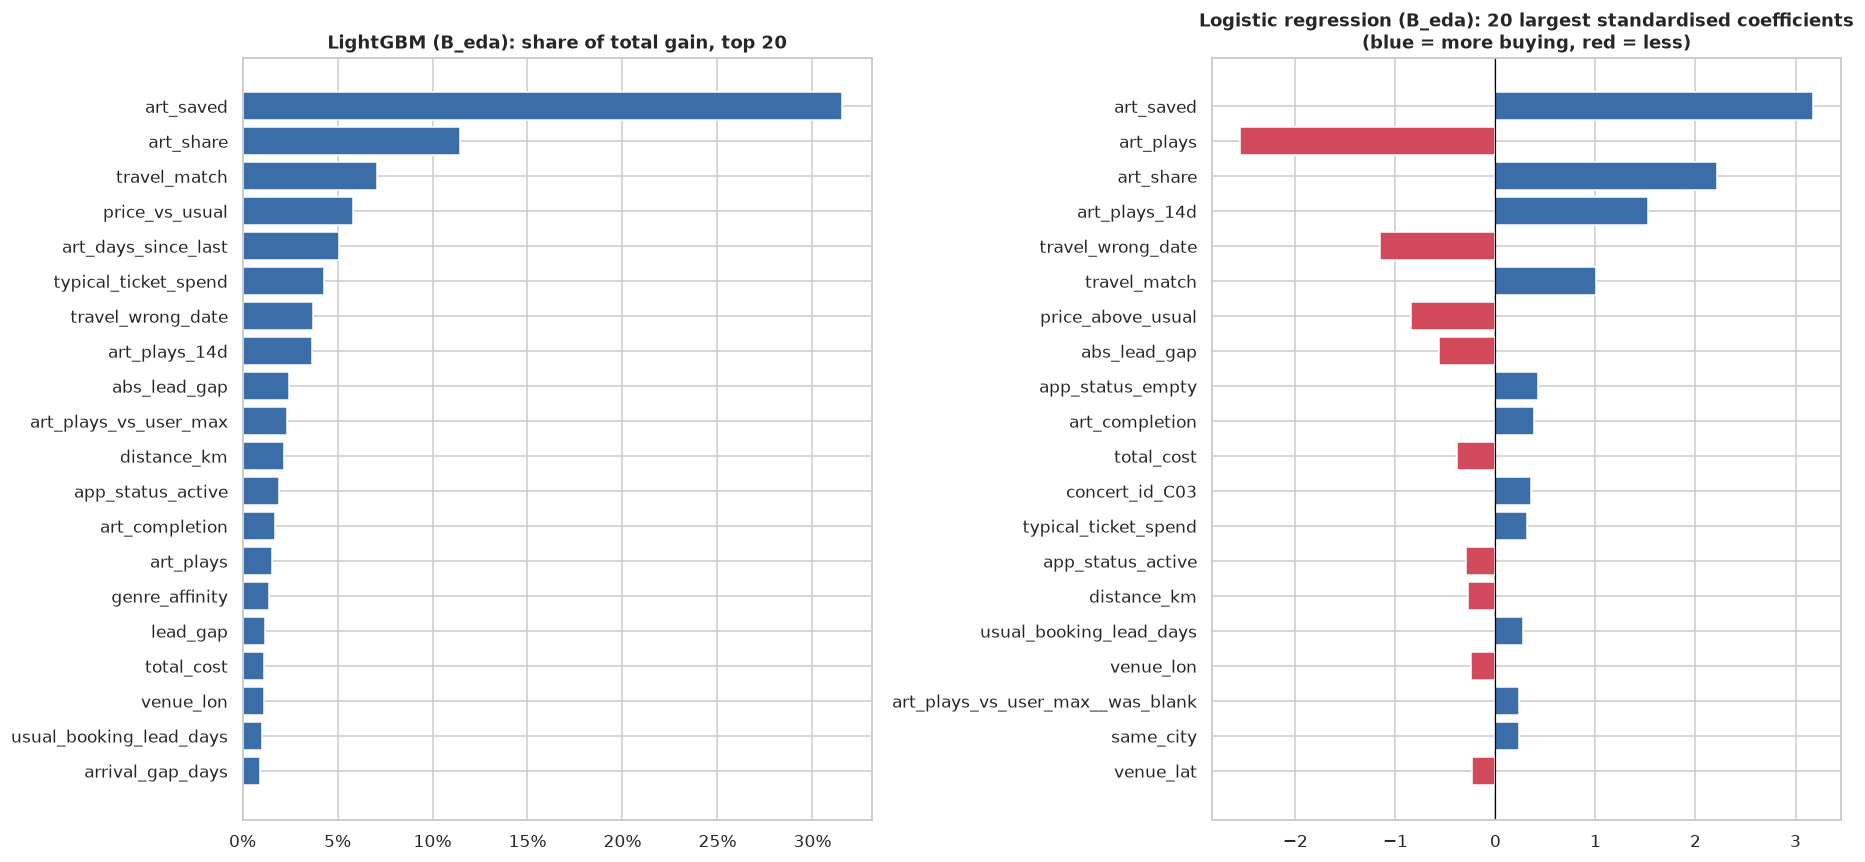

In [13]:
imp = np.zeros(X["B_eda"].shape[1])
for tr, va in FOLDS:
    m = make_lgbm().fit(X["B_eda"].iloc[tr], y[tr])
    imp += m.booster_.feature_importance(importance_type="gain") / N_FOLDS
imp = pd.Series(imp, index=X["B_eda"].columns).sort_values(ascending=False)

lr = make_logreg().fit(X["B_eda"], y)
imputer = lr.named_steps["simpleimputer"]
lr_names = list(X["B_eda"].columns) + [f"{X['B_eda'].columns[i]}__was_blank" for i in imputer.indicator_.features_]
coef = pd.Series(lr.named_steps["logisticregression"].coef_[0], index=lr_names)
coef = coef.reindex(coef.abs().sort_values(ascending=False).index)

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
top = imp.head(20)[::-1]
axes[0].barh(top.index, top.values / imp.sum(), color=BLUE)
axes[0].set_title("LightGBM (B_eda): share of total gain, top 20")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
topc = coef.head(20)[::-1]
axes[1].barh(topc.index, topc.values, color=[BLUE if v > 0 else RED for v in topc.values])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Logistic regression (B_eda): 20 largest standardised coefficients\n(blue = more buying, red = less)")
plt.tight_layout(); plt.show()

> **What I take from this**
> - **LightGBM** leans heavily on `art_saved` (~32% of the total gain), then `art_share`, then **`travel_match` in 3rd place**. Remember in EDA section 11, `travel_match` only had a univariate AUC of 0.57 because it's rare (7.6% of rows). Inside a tree it's one of the most useful splits. Exactly the "rare but precise flag" situation.
> - Then `price_vs_usual`, recency (`art_days_since_last`), `typical_ticket_spend`, `travel_wrong_date`, `art_plays_14d`, `abs_lead_gap`. Basically the top of our EDA feature plan, in roughly the same order. The raw profile columns are not in the top 20.
> - **Logistic regression has a "wrong sign" on `art_plays` (−2.5)**, even though more plays clearly means more buying (EDA 10.5). That's not a bug, it's **multicollinearity**: `art_plays`, `art_share`, `art_saved`, `art_plays_14d` are strongly correlated (EDA section 11), so the model splits the credit between them in a weird way. Holding share, saves and recent plays fixed, extra raw plays get a negative weight. So individual coefficients in this block can't be read on their own. Fixes for later: stronger regularisation (L1 / smaller `C`, lecture 3), keep only one or two of these counts, or compress the block with PCA (lecture 2). Good material for the report.
> - Both models agree on the direction of the clear ones: `travel_match` +, `travel_wrong_date` −, `price_above_usual` −, `abs_lead_gap` −.

---
## 11. Where does it fail?

The overall F1 hides differences between groups. If the model is much worse for one group, that's where the next features should go. I split the OOF predictions of `lgbm_B_eda` (at its best threshold) by concert and by app status.

In [14]:
t = BEST_T["lgbm_B_eda"]
err = train[["concert_id", "artist_name", "app_status", "first_timer", "buy"]].copy()
err["pred"] = (OOF["lgbm_B_eda"] >= t).astype(int)


def group_report(by):
    out = []
    for key, g in err.groupby(by):
        out.append({by: key, "rows": len(g), "buy_rate": g["buy"].mean(), "pred_rate": g["pred"].mean(),
                    "precision": precision_score(g["buy"], g["pred"], zero_division=0),
                    "recall": recall_score(g["buy"], g["pred"], zero_division=0),
                    "F1": f1_score(g["buy"], g["pred"], zero_division=0)})
    return pd.DataFrame(out)


display(group_report("artist_name"))
display(group_report("app_status"))
display(group_report("first_timer"))

,artist_name,rows,buy_rate,pred_rate,precision,recall,F1
0,Kendrick Lamar,6000,0.3292,0.3430,0.8392,0.8744,0.8564
1,Olivia Rodrigo,6000,0.3167,0.3323,0.7969,0.8363,0.8161
2,SZA,6000,0.3647,0.3827,0.8345,0.8757,0.8546
3,Tame Impala,6000,0.2823,0.2922,0.8043,0.8323,0.8181
4,Taylor Swift,6000,0.3882,0.3865,0.8599,0.8562,0.8580


,app_status,rows,buy_rate,pred_rate,precision,recall,F1
0,active,26180,0.3124,0.3144,0.8524,0.8578,0.8551
1,empty,1190,0.4992,0.5840,0.7324,0.8569,0.7898
2,missing,935,0.5091,0.5840,0.7436,0.8529,0.7945
3,no_app,1695,0.4938,0.5593,0.7437,0.8423,0.7899


,first_timer,rows,buy_rate,pred_rate,precision,recall,F1
0,0,21760,0.3246,0.3314,0.8340,0.8515,0.8427
1,1,8240,0.3669,0.3894,0.8171,0.8674,0.8415


> **What I take from this**
> - **By concert**: all between 0.82 and 0.86. Olivia Rodrigo and Tame Impala are the lowest (≈ 0.82), they're also the two concerts with the lowest buy rates. Nothing alarming.
> - **By app status, this is the real gap**: active users F1 ≈ 0.855, but `empty` / `missing` / `no_app` ≈ 0.79. And the model **over-predicts** buying for them: it says yes for ~58% when the true rate is ~50%, so precision drops to ~0.73. Makes sense: for these users the best features (all the listening ones) are blank or 0, so the model only has the weaker CSV signals and falls back on "this group buys a lot".
> - **First-timers vs returning users**: same F1 (0.84), so the missing spend/lead history is handled fine.
> - **→ Priority for the next round of features**: give the model better signals for users without listening data (≈13% of rows, but they're half buyers, so they carry ~19% of all positives).

---
## 12. Final fit and submission files

As the brief says: once we're happy with the CV, **retrain on the whole training set** and predict the test set, with the same preprocessing and the threshold chosen on the OOF predictions.

One honest caveat: the threshold was chosen on models trained on 80% of the users, and the final model sees 100%, so its probabilities can be slightly more confident. With 6,000 users the difference is small, and it's the standard approach. (An alternative some Kagglers use: average the 5 fold models' predictions on test instead of refitting. We can compare both later.)

Two submissions, one per feature set, both with LightGBM:

In [15]:
SUBMISSIONS = {}
for fs in FEATURE_SETS:
    name = f"lgbm_{fs}"
    model = make_lgbm().fit(X[fs], y)
    proba = model.predict_proba(X_test[fs])[:, 1]
    pred = (proba >= BEST_T[name]).astype(int)
    sub = pd.DataFrame({"row_id": test_raw["row_id"], "buy": pred})

    # sanity checks before uploading
    assert sub.shape == (20000, 2)
    assert sub["row_id"].equals(test_raw["row_id"])
    assert set(sub["buy"].unique()) <= {0, 1}

    path = OUT_DIR / f"submission_{name}_t{BEST_T[name]:.2f}.csv"
    sub.to_csv(path, index=False)
    SUBMISSIONS[name] = path
    print(f"{path}: predicted buy rate on test {pred.mean():.3f} "
          f"(OOF predicted rate {(OOF[name] >= BEST_T[name]).mean():.3f}, true train rate {y.mean():.3f})")

pd.read_csv(SUBMISSIONS["lgbm_B_eda"]).head()

submissions/submission_lgbm_A_raw_t0.27.csv: predicted buy rate on test 0.619 (OOF predicted rate 0.609, true train rate 0.336)


submissions/submission_lgbm_B_eda_t0.44.csv: predicted buy rate on test 0.348 (OOF predicted rate 0.347, true train rate 0.336)


,row_id,buy
0,R3770C503,1
1,R216C3DE0,0
2,R315CFF39,0
3,R0CC22A1C,0
4,R30EE7196,1


The predicted buy rate on test is in line with the OOF predicted rate, so nothing weird happened between train and test (no column shift, no broken merge).

### How to submit

1. Kaggle competition page → **Submit Prediction**
2. upload the file from the `submissions/` folder
3. in the description, write what it is, e.g. `lgbm B_eda baseline, t=0.xx, CV F1 0.xxxx` so we can match it with the log later
4. after it's scored, copy the public score into the experiment log below

---
## 13. Experiment log and next steps

From now on, every experiment gets one line in `experiment_log.csv`. At the end of the project this table *is* our report material for section 2 ("report the cross-validated performance [...] as well as the score on the test set").

The `public_lb` column stays empty until we submit; we fill it in by hand.

In [16]:
LOG_PATH = Path("experiment_log.csv")
log_rows = []
for name, p in OOF.items():
    r = RESULTS[(RESULTS["model"] == name.split("_")[0]) & (RESULTS["features"] == "_".join(name.split("_")[1:]))].iloc[0]
    log_rows.append({
        "date": pd.Timestamp.now().strftime("%Y-%m-%d"), "notebook": "02_baseline", "experiment": name,
        "features": "_".join(name.split("_")[1:]), "n_features": X["_".join(name.split("_")[1:])].shape[1],
        "model": name.split("_")[0],
        "params": json.dumps(LGB_PARAMS if name.startswith("lgbm") else {"C": 1.0, "impute": "median+indicator"}),
        "cv": f"StratifiedGroupKFold({N_FOLDS}, seed={SEED})",
        "cv_auc": round(r["AUC"], 4), "cv_f1_at_0.5": round(r["F1@0.5"], 4), "threshold": r["best_threshold"],
        "cv_f1_best": round(r["F1@best"], 4), "cv_f1_fold_std": round(r["fold_std"], 4),
        "submission_file": str(SUBMISSIONS.get(name, "")), "public_lb": "", "notes": "baseline, no tuning",
    })
log = pd.DataFrame(log_rows)
if LOG_PATH.exists():
    old = pd.read_csv(LOG_PATH)
    log = pd.concat([old[~old["experiment"].isin(log["experiment"]) | (old["notebook"] != "02_baseline")], log],
                    ignore_index=True)
log.to_csv(LOG_PATH, index=False)
log

,date,notebook,experiment,features,n_features,model,params,cv,cv_auc,cv_f1_at_0.5,threshold,cv_f1_best,cv_f1_fold_std,submission_file,public_lb,notes
0,2026-11-05,02_baseline,logreg_A_raw,A_raw,50,logreg,"{""C"": 1.0, ""impute"": ""median+indicator""}","StratifiedGroupKFold(5, seed=42)",0.6578,0.2677,0.2600,0.5374,0.0038,,,"baseline, no tuning"
1,2026-11-05,02_baseline,logreg_B_eda,B_eda,81,logreg,"{""C"": 1.0, ""impute"": ""median+indicator""}","StratifiedGroupKFold(5, seed=42)",0.9499,0.8203,0.4000,0.8269,0.0012,,,"baseline, no tuning"
2,2026-11-05,02_baseline,lgbm_A_raw,A_raw,50,lgbm,"{""n_estimators"": 500, ""learning_rate"": 0.03, ""...","StratifiedGroupKFold(5, seed=42)",0.6967,0.3811,0.2700,0.5591,0.0049,submissions/submission_lgbm_A_raw_t0.27.csv,,"baseline, no tuning"
3,2026-11-05,02_baseline,lgbm_B_eda,B_eda,81,lgbm,"{""n_estimators"": 500, ""learning_rate"": 0.03, ""...","StratifiedGroupKFold(5, seed=42)",0.9585,0.8390,0.4400,0.8423,0.0060,submissions/submission_lgbm_B_eda_t0.44.csv,,"baseline, no tuning"


### Next steps

**Tonight / tomorrow**
1. Submit both files to Kaggle (team account), write the public scores in `public_lb` in the log.
2. Check that the public score of `lgbm_B_eda` is close to the CV (≈ 0.84). If it's very different, something is wrong in the pipeline and we fix that before anything else.

**Feature round 1 (LightGBM fixed with the parameters above, so any change in score comes from the features)**
1. **Users without listening data**: what else predicts buying for them? Interactions between engagement / price / travel and `no_listening_data`, maybe a separate small model for them.
2. **Listening refinements** from the EDA "ideas for later": time-decayed play count, search share, saved share, user-level totals (heavy vs light listener), rank by saves instead of plays.
3. **Ablation**: drop one feature group at a time (listening / engagement / offer / geography / profile) and record the F1 drop. That's the "impact of feature combinations" table the report asks for.
4. Clean redundancies (`art_plays_14d` vs `art_days_since_last`, the raw lat/lon columns).

**Later**
- Tuning LightGBM (with early stopping to choose the number of trees), then the model comparison for the report (kNN, random forest, AdaBoost, SVM, LDA, naive Bayes, XGBoost...).
- Move `build_features` into a `features.py` file so the final pipeline is one clean script for the reproducibility requirement.